# Lista de Exercícios 2 — Teoria dos Grafos (Noções de Grafos: Parte 2)

**Instituição:** Instituto Federal Goiano — Campus Iporá (Bacharelado em Ciência da Computação)  
**Disciplina:** Teoria dos Grafos • 3º Período — 2026/2  
**Professor:** Prof. Newarney T. Costa  
**Integrantes:** Messias Junio da Silva Mendes (`Messias-Mendes-Oficial`) | Bruno Alves Mendonça De Abreu Filho  

Este notebook foi projetado para rodar integralmente no **Google Colab** e reúne a modelagem algébrica, verificação computacional e visualização gráfica das **16 questões** da Lista de Exercícios 2.

In [1]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

os.makedirs("prints", exist_ok=True)
plt.rcParams['figure.dpi'] = 130
print("Ambiente Google Colab configurado com sucesso!")

Ambiente Google Colab configurado com sucesso!


## Questão 1 — Representações e Grau via Matriz

Considere o grafo $G = (V, E)$ da figura com vértices $V = \{A, B, C, D\}$ e arestas:
$$e_1 = (A, B), \quad e_2 = (A, C), \quad e_3 = (B, C), \quad e_4 = (B, D), \quad e_5 = (C, D)$$

* **(a) Lista de adjacência:**
  * $A: B, C$
  * $B: A, C, D$
  * $C: A, B, D$
  * $D: B, C$
* **(b) Matriz de adjacência $A$ ($4 \times 4$)** e **(c) Matriz de incidência $B$ ($4 \times 5$):** calculadas abaixo.
* **(d) Interpretação de $A^2$:** Os elementos na diagonal principal $(A^2)_{ii} = d(v_i)$ representam o **grau de cada vértice** ($[2, 3, 3, 2]$), pois um passeio de comprimento 2 que sai de $v_i$ e retorna a $v_i$ num grafo simples consiste em percorrer qualquer aresta incidente a $v_i$ e voltar por ela mesma. Fora da diagonal, $(A^2)_{ij}$ indica o número de passeios de comprimento 2 (vizinhos em comum) entre $v_i$ e $v_j$.
* **(e) Interpretação de $B \cdot B^T$:** Tem dimensão $|V| \times |V| = 4 \times 4$. Na diagonal principal, $(B \cdot B^T)_{ii} = d(v_i)$ é o **grau do vértice $v_i$** (soma dos quadrados das incidências). Fora da diagonal ($i \neq j$), $(B \cdot B^T)_{ij} = A_{ij}$ vale $1$ se os vértices $v_i$ e $v_j$ são adjacentes (compartilham uma aresta) e $0$ caso contrário. Logo, $B \cdot B^T = D + A$.
* **(f) Interpretação de $B^T \cdot B$:** Tem dimensão $|E| \times |E| = 5 \times 5$. Na diagonal principal, $(B^T \cdot B)_{kk} = 2$ para toda aresta $e_k$, pois toda aresta de um grafo simples incide exatamente em **2 vértices**. Fora da diagonal ($k \neq l$), $(B^T \cdot B)_{kl}$ vale $1$ se as arestas $e_k$ e $e_l$ são adjacentes (compartilham um vértice em comum — matriz de adjacência do grafo linha $L(G)$) e $0$ se são arestas disjuntas.

(a) Lista de Adjacência:
  A: B, C
  B: A, C, D
  C: A, B, D
  D: B, C

(b) Matriz de Adjacência A (vértices A, B, C, D):
 [[0 1 1 0]
 [1 0 1 1]
 [1 1 0 1]
 [0 1 1 0]]

(c) Matriz de Incidência B (linhas A..D, colunas e1..e5):
 [[1 1 0 0 0]
 [1 0 1 1 0]
 [0 1 1 0 1]
 [0 0 0 1 1]]

(d) Matriz A² = A · A (Diagonal = graus [2, 3, 3, 2]):
 [[2 1 1 2]
 [1 3 2 1]
 [1 2 3 1]
 [2 1 1 2]]

(e) Matriz B · Bᵀ (Diagonal = graus; Fora da diagonal = A_ij):
 [[2 1 1 0]
 [1 3 1 1]
 [1 1 3 1]
 [0 1 1 2]]

(f) Matriz Bᵀ · B (Diagonal = 2 vértices por aresta; Fora = arestas adjacentes):
 [[2 1 1 1 0]
 [1 2 1 0 1]
 [1 1 2 1 1]
 [1 0 1 2 1]
 [0 1 1 1 2]]


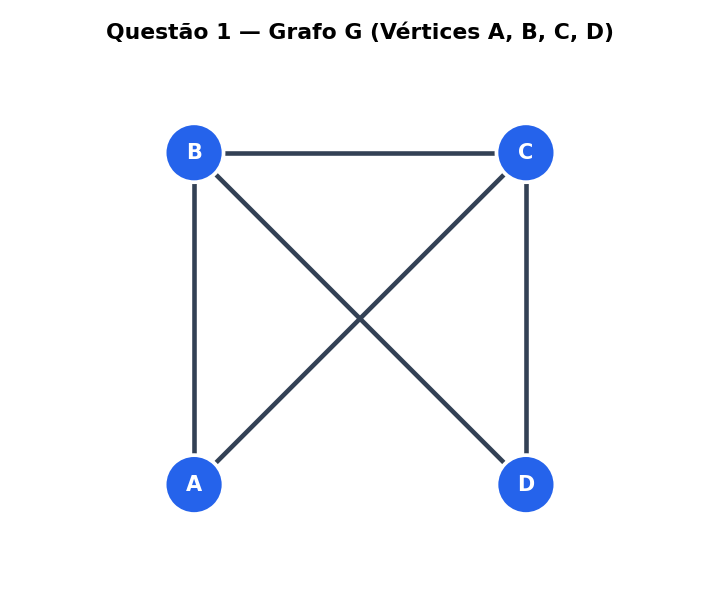

In [2]:
# Questão 1: Lista de Adjacência, Matrizes A, B, A², B·Bᵀ e Bᵀ·B
vertices_q1 = ['A', 'B', 'C', 'D']
arestas_q1 = [('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'D')]

# (a) Lista de Adjacência
adj_q1 = {v: [] for v in vertices_q1}
for u, v in arestas_q1:
    adj_q1[u].append(v)
    adj_q1[v].append(u)

print("(a) Lista de Adjacência:")
for v, viz in adj_q1.items():
    print(f"  {v}: {', '.join(viz)}")

# (b) Matriz de Adjacência A (4x4)
idx = {v: i for i, v in enumerate(vertices_q1)}
A = np.zeros((4, 4), dtype=int)
for u, v in arestas_q1:
    A[idx[u], idx[v]] = 1
    A[idx[v], idx[u]] = 1

# (c) Matriz de Incidência B (4x5)
B = np.zeros((4, 5), dtype=int)
for k, (u, v) in enumerate(arestas_q1):
    B[idx[u], k] = 1
    B[idx[v], k] = 1

A2 = A @ A
BBt = B @ B.T
BtB = B.T @ B

print("\n(b) Matriz de Adjacência A (vértices A, B, C, D):\n", A)
print("\n(c) Matriz de Incidência B (linhas A..D, colunas e1..e5):\n", B)
print("\n(d) Matriz A² = A · A (Diagonal = graus [2, 3, 3, 2]):\n", A2)
print("\n(e) Matriz B · Bᵀ (Diagonal = graus; Fora da diagonal = A_ij):\n", BBt)
print("\n(f) Matriz Bᵀ · B (Diagonal = 2 vértices por aresta; Fora = arestas adjacentes):\n", BtB)

## Questão 2 — Listas de Adjacência Não Simétricas (Economia de Índices)

Na lista de adjacência original (simétrica, grafo não orientado com $n=7$ vértices e $m=8$ arestas), cada aresta $\{u, v\}$ aparece duplicada (uma vez na lista de $u$ e outra na lista de $v$), totalizando $2m = 16$ índices armazenados.  
Para transformá-la em uma **lista não simétrica** (orientando cada aresta de $u$ para $v$ com $u < v$), armazenamos apenas os vizinhos $v > u$, reduzindo o total de índices pela metade ($m = 8$):

In [3]:
# Questão 2: Transformação em listas de adjacência não simétricas (v > u)
lista_simetrica = {
    1: [2, 4],
    2: [1, 3, 4],
    3: [2, 4],
    4: [1, 2, 3, 5],
    5: [4, 6],
    6: [5, 7],
    7: [6]
}

lista_nao_simetrica = {u: [v for v in viz if v > u] for u, viz in lista_simetrica.items()}

print("Vértice | Lista Simétrica (Original) | Lista Não Simétrica (v > u)")
print("-" * 66)
for u in sorted(lista_simetrica):
    orig = ", ".join(map(str, lista_simetrica[u]))
    nsim = ", ".join(map(str, lista_nao_simetrica[u])) if lista_nao_simetrica[u] else "∅ (vazia)"
    print(f"   {u}    | {orig:<26} | {nsim}")

total_orig = sum(len(v) for v in lista_simetrica.values())
total_nsim = sum(len(v) for v in lista_nao_simetrica.values())
print(f"\nTotal de índices antes: {total_orig} (2m) -> Após otimização: {total_nsim} (m). Economia de 50%.")

Vértice | Lista Simétrica (Original) | Lista Não Simétrica (v > u)
------------------------------------------------------------------
   1    | 2, 4                       | 2, 4
   2    | 1, 3, 4                    | 3, 4
   3    | 2, 4                       | 4
   4    | 1, 2, 3, 5                 | 5
   5    | 4, 6                       | 6
   6    | 5, 7                       | 7
   7    | 6                          | ∅ (vazia)

Total de índices antes: 16 (2m) -> Após otimização: 8 (m). Economia de 50%.


## Questão 3 — Grafo Completo / Universo e Complementar

* **Grafo-universo (completo) não orientado ($K_n$):** Possui todas as arestas possíveis entre pares distintos de vértices:
  $$|E(K_n)| = \binom{n}{2} = \frac{n(n-1)}{2}$$
  Para $n = 4$ vértices, $K_4$ possui $\frac{4 \times 3}{2} = 6$ arestas (soma das $3$ arestas de $G$ com as $3$ arestas de $\overline{G}$).
* **Grafo-universo (completo) orientado:**
  * **Sem laços ($K_n^*$):** Para cada par ordenado $(u, v)$ com $u \neq v$, existe um arco, totalizando **$n(n-1)$ arcos** (para $n=4$, são $4 \times 3 = 12$ arcos: $8$ arcos em $G$ e $4$ arcos em $\overline{G}$, exatamente como na figura da questão!).
  * *(Observação: Caso a convenção admita auto-laços em cada vértice no grafo-universo orientado, o total é $n^2 = 16$ arcos).*

n =  4 vértices -> K_n não orientado:  6 arestas | Orientado (sem laços): 12 arcos | (com laços):  16 arcos
n =  5 vértices -> K_n não orientado: 10 arestas | Orientado (sem laços): 20 arcos | (com laços):  25 arcos
n =  6 vértices -> K_n não orientado: 15 arestas | Orientado (sem laços): 30 arcos | (com laços):  36 arcos
n = 10 vértices -> K_n não orientado: 45 arestas | Orientado (sem laços): 90 arcos | (com laços): 100 arcos


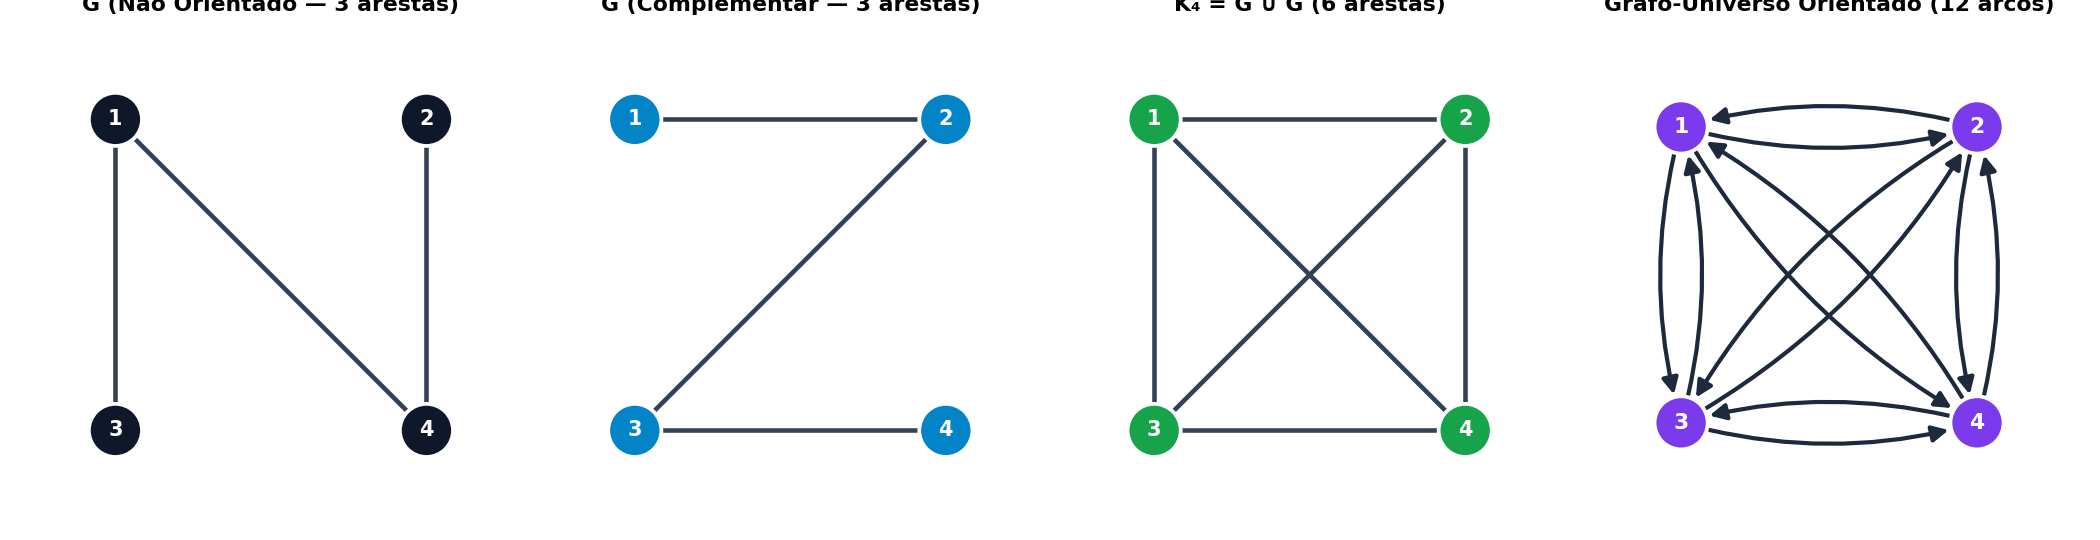

In [4]:
# Questão 3: Contagem de arestas e arcos para n = 4 (e fórmula geral)
for n in [4, 5, 6, 10]:
    arestas_kn = n * (n - 1) // 2
    arcos_sem_lacos = n * (n - 1)
    arcos_com_lacos = n ** 2
    print(f"n = {n:2d} vértices -> K_n não orientado: {arestas_kn:2d} arestas | Orientado (sem laços): {arcos_sem_lacos:2d} arcos | (com laços): {arcos_com_lacos:3d} arcos")

## Questão 4 — Grau e Lema do Aperto de Mãos

* **(a) Soma dos graus é igual ao dobro do número de arestas ($\sum_{v \in V} d(v) = 2m$):**
  Cada aresta $e = \{u, v\} \in E$ possui exatamente duas extremidades e, portanto, contribui com $+1$ para o grau de $u$ e $+1$ para o grau de $v$ (ou $+2$ no grau de $u$ se for um laço). Somando as contribuições de todas as $m = |E|$ arestas sobre todos os vértices, obtemos $\sum_{v \in V} d(v) = 2m$.
* **(b) O número de vértices de grau ímpar é sempre par:**
  Particionando $V$ no subconjunto de vértices de grau par ($V_{\text{par}}$) e de grau ímpar ($V_{\text{ímpar}}$):
  $$\sum_{v \in V_{\text{ímpar}}} d(v) = 2m - \sum_{v \in V_{\text{par}}} d(v)$$
  Como $2m$ é par e a soma de números pares ($\sum_{v \in V_{\text{par}}} d(v)$) também é par, a diferença no lado direito é **par**. Para que uma soma de números ímpares resulte em um número par, a quantidade de parcelas ($|V_{\text{ímpar}}|$) precisa obrigatoriamente ser **par**.

## Questão 5 — Graus e Semigraus ($d^+, d^-$)

=== Grafo Não Orientado (Esquerda) ===
  Vértice 1: d(1) = 3
  Vértice 2: d(2) = 3
  Vértice 3: d(3) = 3
  Vértice 4: d(4) = 2
  Vértice 5: d(5) = 2
  Vértice 6: d(6) = 3
  Soma dos graus = 16 = 2 * 8 arestas (Vértices ímpares: 4)

=== Grafo Orientado (Direita) ===
  Vértice | d⁺ (Saída/Emissão) | d⁻ (Entrada/Recepção) | Grau Total d(v) = d⁺ + d⁻
  ------------------------------------------------------------------------
     1    |         2          |           1           |            3
     2    |         2          |           1           |            3
     3    |         2          |           1           |            3
     4    |         1          |           1           |            2
     5    |         1          |           1           |            2
     6    |         0          |           3           |            3
  Soma d⁺ = 8 | Soma d⁻ = 8 | Total de arcos = 8


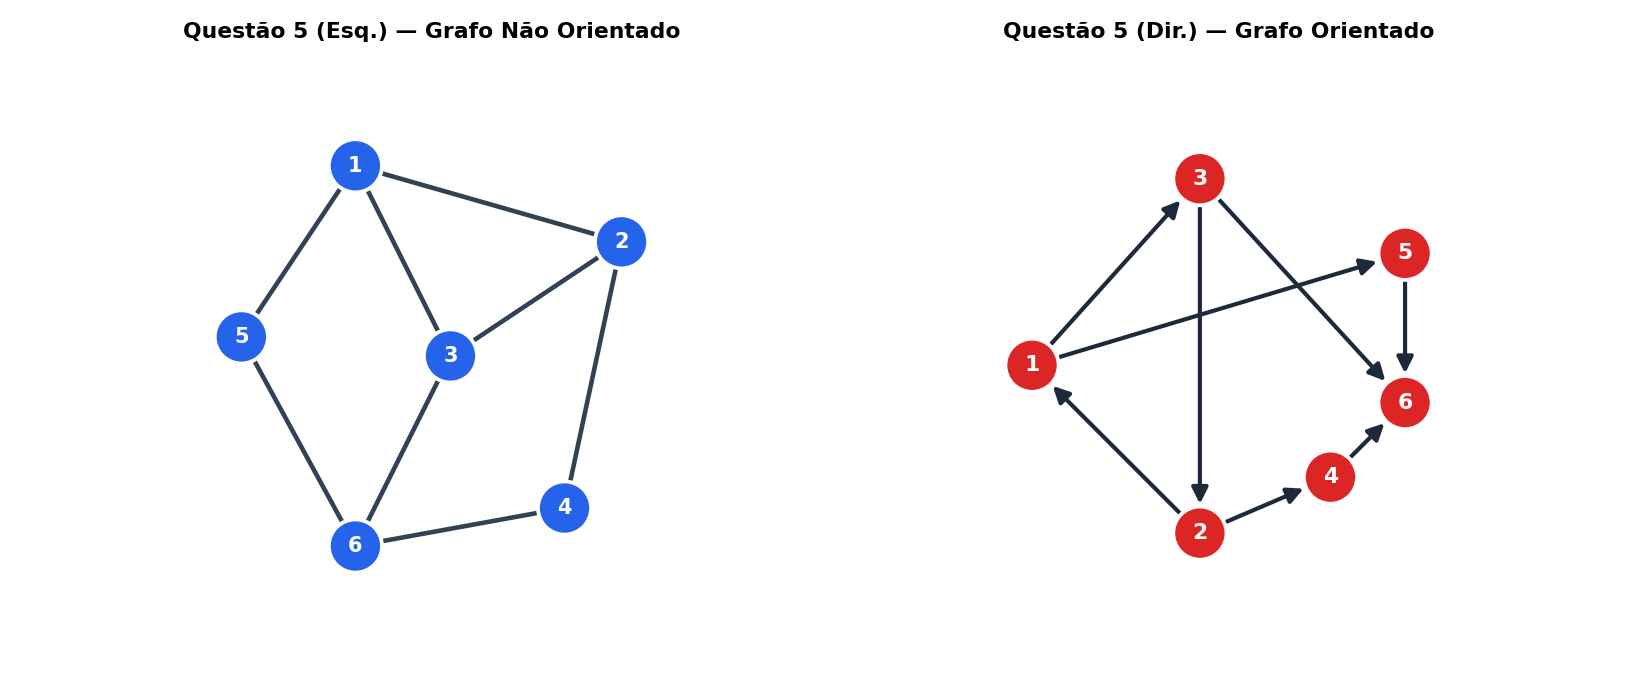

In [5]:
# Questão 5: Graus do grafo não orientado (esq.) e Semigraus do grafo orientado (dir.)
arestas_q5_esq = [(1, 2), (1, 3), (1, 5), (2, 3), (2, 4), (3, 6), (4, 6), (5, 6)]
graus_esq = {v: 0 for v in range(1, 7)}
for u, v in arestas_q5_esq:
    graus_esq[u] += 1
    graus_esq[v] += 1

print("=== Grafo Não Orientado (Esquerda) ===")
for v, g in graus_esq.items():
    print(f"  Vértice {v}: d({v}) = {g}")
print(f"  Soma dos graus = {sum(graus_esq.values())} = 2 * {len(arestas_q5_esq)} arestas (Vértices ímpares: {sum(1 for g in graus_esq.values() if g % 2 == 1)})")

arcos_q5_dir = [(1, 3), (1, 5), (2, 1), (2, 4), (3, 2), (3, 6), (4, 6), (5, 6)]
d_out = {v: 0 for v in range(1, 7)}
d_in  = {v: 0 for v in range(1, 7)}
for u, v in arcos_q5_dir:
    d_out[u] += 1
    d_in[v] += 1

print("\n=== Grafo Orientado (Direita) ===")
print("  Vértice | d⁺ (Saída/Emissão) | d⁻ (Entrada/Recepção) | Grau Total d(v) = d⁺ + d⁻")
print("  " + "-"*72)
for v in range(1, 7):
    print(f"     {v}    |         {d_out[v]}          |           {d_in[v]}           |            {d_out[v] + d_in[v]}")
print(f"  Soma d⁺ = {sum(d_out.values())} | Soma d⁻ = {sum(d_in.values())} | Total de arcos = {len(arcos_q5_dir)}")

## Questão 6 — Grafo Bipartido e Isomorfismo

* **(a) Demonstração de que um grafo bipartido não tem ciclos ímpares:**
  Seja $G = (X \cup Y, E)$ bipartido com partições disjuntas $X$ e $Y$. Toda aresta liga um vértice de $X$ a um vértice de $Y$. Ao percorrer qualquer ciclo $C = v_1, v_2, \dots, v_k, v_1$, os vértices alternam obrigatoriamente entre $X$ e $Y$. Sem perda de generalidade, se $v_1 \in X$, então os vértices de índice ímpar pertencem a $X$ e os de índice par pertencem a $Y$. Para fechar o ciclo com a aresta $(v_k, v_1)$ onde $v_1 \in X$, o último vértice $v_k$ deve pertencer a $Y$, logo $k$ é **par**. Portanto, $G$ não possui ciclos de comprimento ímpar.
* **(b) A recíproca é verdadeira?**
  **Sim** (Teorema de König): se um grafo não possui ciclos ímpares, podemos escolher um vértice raiz $r$ em cada componente conexa e definir $X = \{v \mid \text{dist}(r, v) \text{ é par}\}$ e $Y = \{v \mid \text{dist}(r, v) \text{ é ímpar}\}$. Dois vértices na mesma partição nunca são adjacentes, pois isso formaria um ciclo fechado de comprimento ímpar. Logo, $G$ é bipartido.
* **(c) Mostrar que os dois grafos da figura não são isomorfos usando (a):**
  * **Grafo da direita ($Q_3$, cubo):** É **bipartido** (bicoloração $X = \{1, 3, 6, 8\}$ e $Y = \{2, 4, 5, 7\}$), não possuindo nenhum ciclo ímpar.
  * **Grafo da esquerda:** As ligações cruzadas na parte inferior formam o ciclo ímpar de comprimento 5: $1 - 5 - 8 - 3 - 4 - 1$ ($C_5$). Pelo item (a), o grafo da esquerda **não é bipartido**. Como a bipartição é um invariante por isomorfismo, os dois grafos **não são isomorfos**.

Grafo 1 (Esquerda) é bipartido? False -> Conflito de mesma cor na aresta (3, 8) (Ciclo ímpar C₅: 1-5-8-3-4-1)
Grafo 2 (Direita)  é bipartido? True  -> Partições X=[1, 3, 6, 8], Y=[2, 4, 5, 7]
Conclusão: Como G₂ é bipartido e G₁ não é bipartido, G₁ e G₂ NÃO são isomorfos!


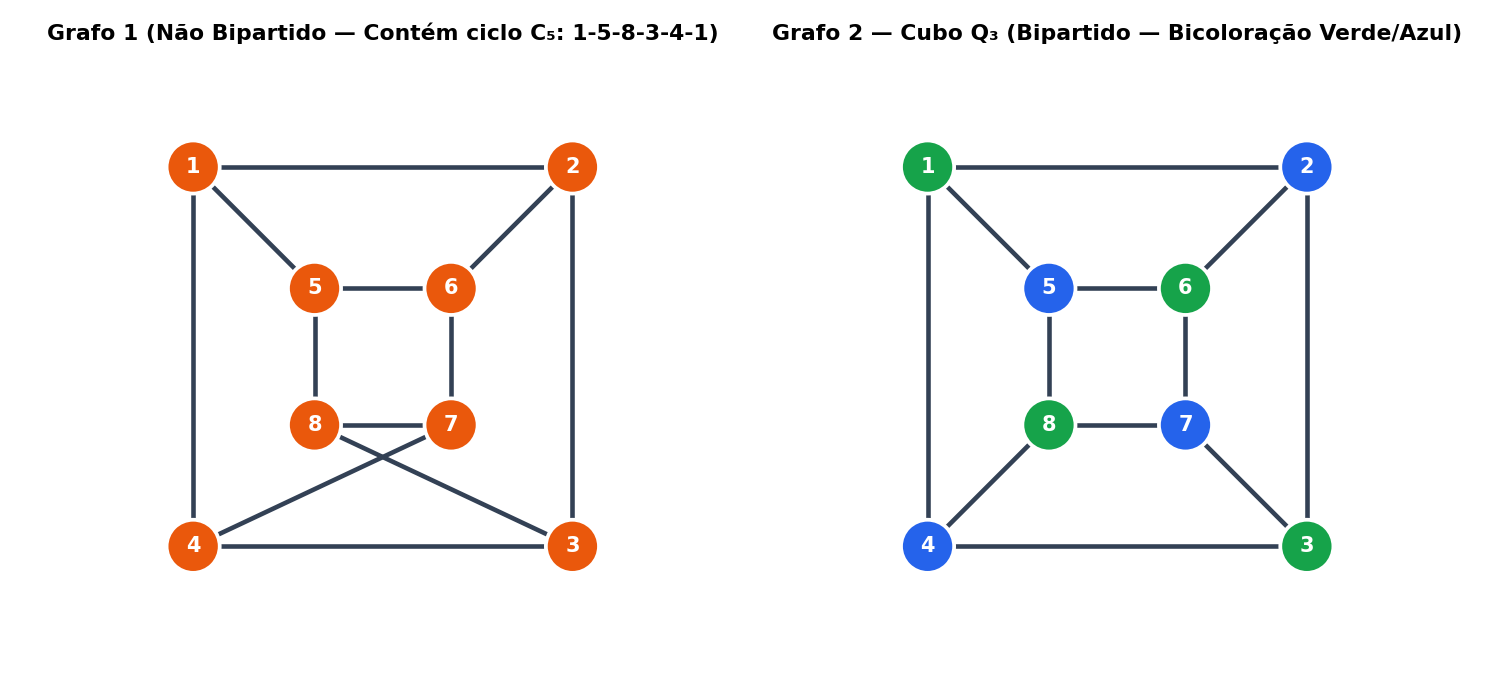

In [6]:
# Questão 6(c): Verificação via BFS de Bipartição (2-coloração) e detecção de ciclo ímpar
def verificar_bipartido(vertices, arestas):
    adj = {v: [] for v in vertices}
    for u, v in arestas:
        adj[u].append(v)
        adj[v].append(u)
    cor = {}
    for s in vertices:
        if s not in cor:
            cor[s] = 0
            fila = [s]
            while fila:
                u = fila.pop(0)
                for v in adj[u]:
                    if v not in cor:
                        cor[v] = 1 - cor[u]
                        fila.append(v)
                    elif cor[v] == cor[u]:
                        return False, cor, (u, v)
    return True, cor, None

nodes_q6 = [1, 2, 3, 4, 5, 6, 7, 8]
edges_g1 = [(1,2),(2,3),(3,4),(4,1), (5,6),(6,7),(7,8),(8,5), (1,5),(2,6),(4,7),(3,8)]
edges_g2 = [(1,2),(2,3),(3,4),(4,1), (5,6),(6,7),(7,8),(8,5), (1,5),(2,6),(3,7),(4,8)]

bip1, cor1, conflito1 = verificar_bipartido(nodes_q6, edges_g1)
bip2, cor2, _ = verificar_bipartido(nodes_q6, edges_g2)

print(f"Grafo 1 (Esquerda) é bipartido? {bip1} -> Conflito de mesma cor na aresta {conflito1} (Ciclo ímpar C₅: 1-5-8-3-4-1)")
print(f"Grafo 2 (Direita)  é bipartido? {bip2}  -> Partições X={[k for k,v in cor2.items() if v==0]}, Y={[k for k,v in cor2.items() if v==1]}")
print("Conclusão: Como G₂ é bipartido e G₁ não é bipartido, G₁ e G₂ NÃO são isomorfos!")

## Questão 7 — Percursos: Cadeia, Ciclo, Circuito, Simples e Elementar

Seguindo estritamente o **Glossário** da página 4 da lista:
* **Percurso (cadeia):** sequência alternada de vértices e ligações consecutivas.
* **Fechado:** começa e termina no mesmo vértice.
* **Simples:** não repete ligações (arestas/arcos).
* **Elementar:** não repete vértices (salvo o primeiro e o último se for fechado).
* **Ciclo:** percurso fechado e elementar (grafo não orientado).
* **Circuito:** percurso fechado que respeita a orientação (grafo orientado).

| Item / Grafo | Análise e Classificação |
| :--- | :--- |
| **(a) $G_1$** | Grafo não orientado: percurso **aberto, simples e elementar** (não repete arestas nem vértices). |
| **(a) $G_2$** | Grafo orientado: percurso orientado **aberto, simples e elementar** (respeita as setas sem repetir vértices ou arcos). |
| **(a) $G_4$** | Grafo orientado: percurso **aberto, simples, mas NÃO elementar** (repete o segundo vértice superior ao passar pelo triângulo antes de seguir à direita) / ou verificar sentido dos arcos. |
| **(a) $G_5$** | Grafo não orientado: percurso **fechado, simples e elementar** $\Rightarrow$ é um **Ciclo** ($C_4$). |
| **(a) $G_6$** | Grafo orientado: percurso **fechado, simples e elementar** que respeita a orientação de todos os 4 arcos $\Rightarrow$ é um **Circuito** elementar. |
| **(a) $G_7$** | Grafo orientado: as setas realçadas não seguem todas o mesmo sentido de giro (há arcos em sentidos opostos no quadrilátero), logo é uma **cadeia fechada simples e elementar**, mas **não é um circuito** (pois não respeita a orientação). |
| **(b) $G_3$** | **Simples (e elementar):** ir de um vértice do triângulo esquerdo até um do triângulo direito passando pela ponte central sem repetir vértices. **Simples mas não elementar:** percorrer o triângulo esquerdo inteiro, atravessar a ponte central e percorrer o triângulo direito (repete os vértices de articulação dos triângulos, mas não repete arestas). **Não simples:** atravessar a aresta ponte central na ida e na volta (repete a aresta ponte). |
| **(c) $G_6$ e $G_7$** | Pelo glossário da lista, *ciclo* aplica-se a grafo não orientado e *circuito* a grafo orientado que respeita a orientação. Assim, o percurso fechado em **$G_6$ é um circuito** (respeita a orientação), enquanto em **$G_7$ não é um circuito** (não respeita a orientação dos arcos). |
| **(d) Elementar $\leftrightarrow$ Simples** | **Todo percurso elementar é simples?** **Sim**, pois se um percurso repetisse uma ligação (aresta/arco), obrigatoriamente repetiria seus vértices extremos. **Todo percurso simples é elementar?** **Não** (contraexemplo em $G_3$: contornar dois triângulos unidos por um vértice ou ponte sem repetir arestas repete o vértice de junção). |
| **(e) Não elementares em $G_5$ a $G_7$** | Basta partir do vértice superior direito (grau 1), ir até o vértice de junção do quadrilátero, dar a volta completa no quadrilátero (repetindo o vértice de junção) e parar (ou dar duas voltas no quadrilátero). |

## Questão 8 — Clique, Grafo Complementar e Bipartido Completo

* **Conclusão sobre o clique:** No grafo $G$ da figura, os 4 vértices brancos centrais formam um **clique** $K_4$ (todos mutuamente adjacentes). Ao construir o **grafo complementar $\overline{G}$**, todas as arestas internas ao clique desaparecem, transformando o clique de $G$ em um **conjunto independente** (subconjunto de vértices sem nenhuma aresta entre si) em $\overline{G}$!
* **Grafo bipartido completo ($K_{p,q}$) e seu complementar:**
  * Um grafo bipartido com partições $X$ ($|X|=p$) e $Y$ ($|Y|=q$) torna-se **bipartido completo ($K_{p,q}$)** adicionando-se todas as arestas que faltam entre cada vértice $x \in X$ e cada vértice $y \in Y$ (total de $p \cdot q$ arestas, sem nenhuma aresta interna a $X$ ou a $Y$).
  * O **complementar de um grafo bipartido completo** $\overline{K_{p,q}}$ remove todas as arestas entre $X$ e $Y$ e adiciona todas as arestas internas a $X$ e internas a $Y$, resultando na **união disjunta de dois cliques (grafos completos)**: $\overline{K_{p,q}} = K_p \cup K_q$.

## Questão 9 — Isomorfismo ($n=5$ vértices)

* **(a) Dois grafos de 5 vértices e 8 arestas não isomorfos:**
  Como $K_5$ possui $\binom{5}{2} = 10$ arestas, um grafo $G$ com $5$ vértices e $8$ arestas tem um **grafo complementar $\overline{G}$ com $5$ vértices e apenas $10 - 8 = 2$ arestas**!  
  Dois grafos são isomorfos se e somente se seus complementares são isomorfos. Com $2$ arestas, existem exatamente **2 configurações não isomorfas** para $\overline{G}$:
  1. **Duas arestas adjacentes** (caminho $P_3$ + 2 vértices isolados) $\Rightarrow$ no grafo $H_1$ (8 arestas), a sequência de graus é **$(4, 4, 3, 3, 2)$**.
  2. **Duas arestas disjuntas** (emparelhamento $2K_2$ + 1 vértice isolado) $\Rightarrow$ no grafo $H_2$ (8 arestas), a sequência de graus é **$(4, 3, 3, 3, 3)$**.
* **(b) Com 5 vértices e 7 arestas, quantos grafos não isomorfos podemos ter?**
  O complementar $\overline{G}$ possui $5$ vértices e $10 - 7 = 3$ arestas. Existem exatamente **4 grafos não isomorfos** com 5 vértices e 3 arestas (e, portanto, **4 grafos não isomorfos** com 5 vértices e 7 arestas):
  1. Complementar = Triângulo $K_3 \cup 2K_1$ $\Rightarrow$ Graus em $G$: $(4, 4, 2, 2, 2)$
  2. Complementar = Estrela $K_{1,3} \cup K_1$ $\Rightarrow$ Graus em $G$: $(4, 3, 3, 3, 1)$
  3. Complementar = Caminho $P_4 \cup K_1$ $\Rightarrow$ Graus em $G$: $(4, 3, 3, 2, 2)$
  4. Complementar = $P_3 \cup K_2$ (uma aresta + um $P_3$ disjunto) $\Rightarrow$ Graus em $G$: $(3, 3, 3, 3, 2)$

## Questão 10 — Sequência de Graus (Realizabilidade)

**Enunciado:** Construa um grafo com 10 vértices e graus $(9, 7, 6, 4, 3, 3, 3, 1, 1, 1)$, ou mostre ser impossível.

**Demonstração de Impossibilidade:**
1. Seja $V = \{v_1, v_2, \dots, v_{10}\}$ ordenado pelos graus $(9, 7, 6, 4, 3, 3, 3, 1, 1, 1)$.
2. O vértice $v_1$ tem grau $9$. Como o grafo simples possui $10$ vértices, $v_1$ está obrigatoriamente conectado a **todos os outros 9 vértices** ($v_2, v_3, \dots, v_{10}$).
3. Os vértices $v_8, v_9, v_{10}$ possuem grau $1$. Como já estão conectados a $v_1$, suas únicas arestas são $(v_1, v_8), (v_1, v_9)$ e $(v_1, v_{10})$ — eles **não podem se conectar a mais nenhum outro vértice**!
4. Assim, para o vértice $v_2$ (que exigiria grau $7$), os únicos vizinhos possíveis são $v_1, v_3, v_4, v_5, v_6, v_7$ — ou seja, no máximo **6 vértices**! Logo, o grau máximo que $v_2$ poderia atingir é $6 < 7$, uma contradição. Portanto, **é impossível** (a sequência não é gráfica).

## Questão 11 — Grafo Regular e Paridade

**Enunciado:** Mostre que não existem grafos $(2k-1)$-regulares com $2r-1$ vértices ($k, r \in \{1, 2, 3, \dots\}$).

**Demonstração:**
Em um grafo $(2k-1)$-regular com $n = 2r-1$ vértices, todos os vértices possuem grau ímpar $d(v) = 2k-1$, e o número total de vértices $n = 2r-1$ também é ímpar.  
Pelo **Lema do Aperto de Mãos** (Questão 4a), a soma dos graus deve ser par ($2m$):
$$\sum_{v \in V} d(v) = (2r-1)(2k-1) = 2m$$
Porém, o produto de dois números ímpares $(2r-1)$ e $(2k-1)$ é sempre **ímpar**, enquanto $2m$ é sempre **par** — contradição! (Equivalentemente, pelo item 4b, o número de vértices de grau ímpar deve ser par, mas aqui haveria $2r-1$ vértices de grau ímpar).

=== Questão 10: Teste de Havel-Hakimi para (9, 7, 6, 4, 3, 3, 3, 1, 1, 1) ===
  Passo 0: [9, 7, 6, 4, 3, 3, 3, 1, 1, 1]
  Passo 1: [6, 5, 3, 2, 2, 2, 0, 0, 0]
  Passo 2: [4, 2, 1, 1, 1, -1, 0, 0]
  Sequência é gráfica/realizável? False (Contradição já no Passo 2: grau 6 precisaria de 6 vizinhos positivos, mas só restam 5!)


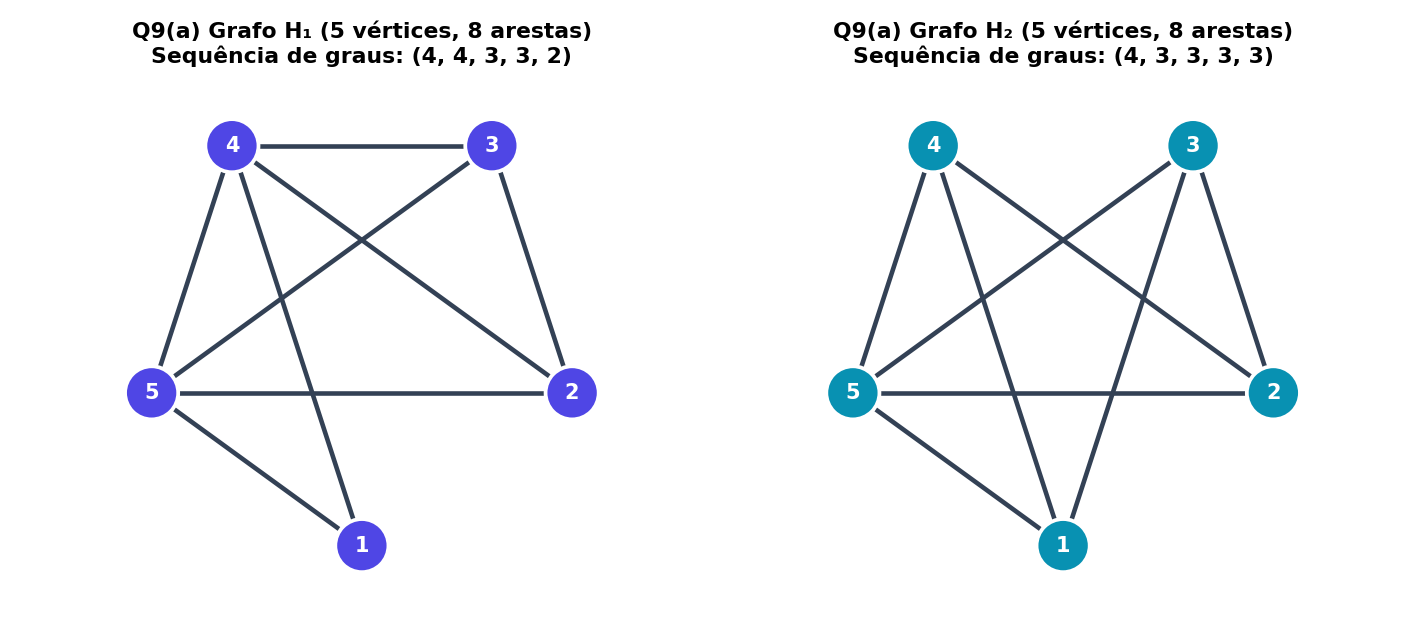

In [7]:
# Verificação Computacional das Questões 9 e 10 (Algoritmo de Havel-Hakimi)
def havel_hakimi(seq):
    s = sorted(seq, reverse=True)
    passos = [list(s)]
    while any(x > 0 for x in s):
        d1 = s.pop(0)
        if d1 > len(s):
            return False, passos
        for i in range(d1):
            s[i] -= 1
            if s[i] < 0:
                passos.append(list(s))
                return False, passos
        s.sort(reverse=True)
        passos.append(list(s))
    return True, passos

seq_q10 = [9, 7, 6, 4, 3, 3, 3, 1, 1, 1]
realizavel, etapas = havel_hakimi(seq_q10)
print("=== Questão 10: Teste de Havel-Hakimi para (9, 7, 6, 4, 3, 3, 3, 1, 1, 1) ===")
for i, et in enumerate(etapas):
    print(f"  Passo {i}: {et}")
print(f"  Sequência é gráfica/realizável? {realizavel} (Contradição já no Passo 2: grau 6 precisaria de 6 vizinhos positivos, mas só restam 5!)")

## Questão 12 — Conexidade em Grafos Orientados

Classificação de conexidade em dígrafos $D = (V, A)$:
1. **Não conexo:** O grafo subjacente não orientado é desconexo.
2. **$s$-conexo (simplesmente / fracamente conexo):** O grafo subjacente não orientado é conexo.
3. **$sf$-conexo (semifortemente / unilateralmente conexo):** Para todo par de vértices $u, v \in V$, existe um caminho dirigido de $u$ para $v$ **ou** de $v$ para $u$.
4. **$f$-conexo (fortemente conexo):** Para todo par de vértices $u, v \in V$, existe um caminho dirigido de $u$ para $v$ **e** um caminho dirigido de $v$ para $u$.

## Questão 13 — Existência de Caminho Abrangente em Grafos $sf$-conexos e $f$-conexos

**Demonstração:**
* **Caso $f$-conexo:** Se $G$ é fortemente conexo, para quaisquer vértices $v_1, v_2, \dots, v_n$, existe um caminho dirigido de $v_i$ até $v_{i+1}$ para todo $i = 1, \dots, n-1$. Concatenando esses caminhos dirigidos $v_1 \leadsto v_2 \leadsto \dots \leadsto v_n$, obtemos um caminho (passeio dirigido, não necessariamente simples) que passa por todos os vértices de $G$. (E como todo grafo $f$-conexo é também $sf$-conexo, provar para $sf$-conexo implica imediatamente o resultado para $f$-conexo).
* **Caso $sf$-conexo:** Sejam $C_1, C_2, \dots, C_k$ as componentes fortemente conexas (CFCs) de $G$. O grafo reduzido (condensado) $G_{\text{red}}$ é acíclico (DAG) e também $sf$-conexo. Em um DAG, ser $sf$-conexo equivale a possuir uma **única ordenação topológica linear** $C_1 \to C_2 \to \dots \to C_k$ tal que existe pelo menos um arco de $C_i$ para $C_{i+1}$. Como cada $C_i$ é internamente fortemente conexa, podemos percorrer todos os vértices dentro de $C_1$, atravessar o arco para $C_2$, percorrer todos os vértices de $C_2$, e assim sucessivamente até $C_k$, visitando todos os vértices do grafo!

## Questão 14 — Componentes Fortemente Conexas e Algoritmo de Malgrange

**Explicação do Algoritmo de Malgrange:**
Para encontrar as Componentes Fortemente Conexas (CFCs) de um dígrafo $G = (V, A)$:
1. Escolha um vértice ainda não classificado $v \in V$.
2. Calcule o **fecho transitivo direto** $\Gamma^+(v)$: conjunto de todos os vértices alcançáveis a partir de $v$ (incluindo $v$).
3. Calcule o **fecho transitivo inverso** $\Gamma^-(v)$: conjunto de todos os vértices a partir dos quais é possível alcançar $v$ (incluindo $v$).
4. A componente fortemente conexa de $v$ é dada pela interseção:
   $$C(v) = \Gamma^+(v) \cap \Gamma^-(v)$$
5. Remova os vértices de $C(v)$ e repita o processo até que todos os vértices de $V$ pertençam a uma CFC.

=== Execução do Algoritmo de Malgrange ===
Iteração 1 (Pivô v = 'A'):
  Γ⁺(A) = ['A', 'B', 'C', 'D', 'E', 'F']
  Γ⁻(A) = ['A', 'B', 'C']
  CFC C_1 = Γ⁺(A) ∩ Γ⁻(A) = ['A', 'B', 'C']

Iteração 2 (Pivô v = 'D'):
  Γ⁺(D) = ['D', 'E', 'F']
  Γ⁻(D) = ['A', 'B', 'C', 'D', 'E']
  CFC C_2 = Γ⁺(D) ∩ Γ⁻(D) = ['D', 'E']

Iteração 3 (Pivô v = 'F'):
  Γ⁺(F) = ['F']
  Γ⁻(F) = ['A', 'B', 'C', 'D', 'E', 'F']
  CFC C_3 = Γ⁺(F) ∩ Γ⁻(F) = ['F']


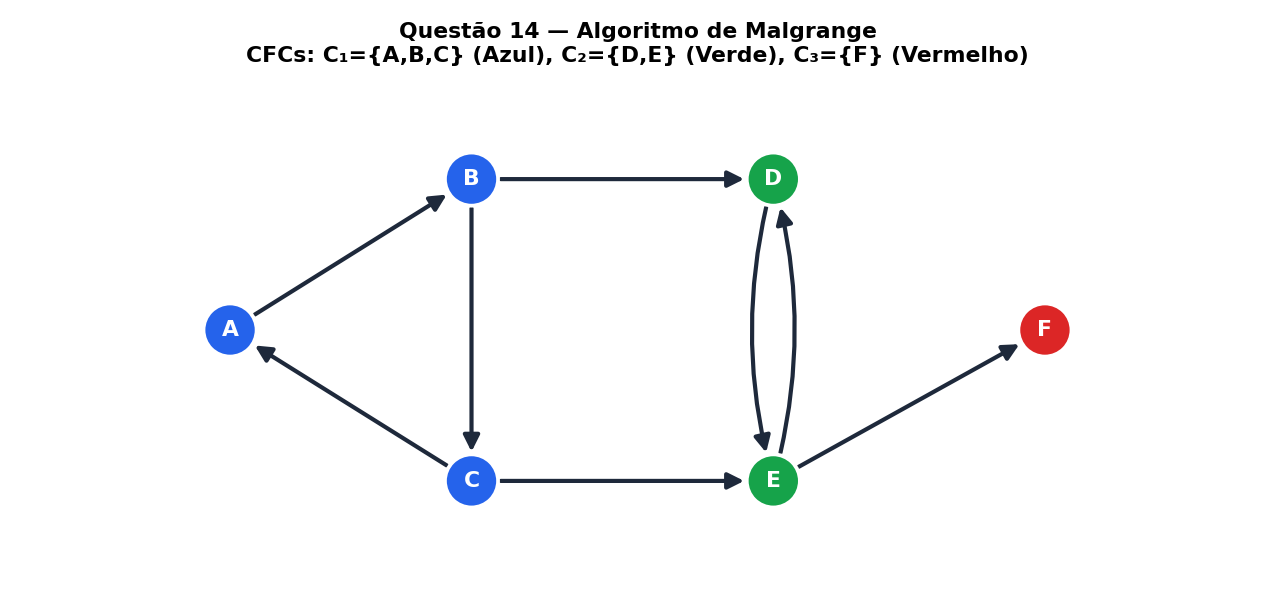

In [8]:
# Questão 14: Implementação Passo a Passo do Algoritmo de Malgrange
vertices_q14 = ['A', 'B', 'C', 'D', 'E', 'F']
arcos_q14 = [
    ('A', 'B'), ('B', 'C'), ('C', 'A'), # Ciclo entre A, B, C
    ('B', 'D'), ('C', 'E'),             # Ligações para D e E
    ('D', 'E'), ('E', 'D'),             # Ciclo entre D e E
    ('E', 'F')                          # Saída para F (sumidouro)
]

def fecho_transitivo(inicio, vertices, arcos, inverso=False):
    visitados = {inicio}
    fila = [inicio]
    while fila:
        u = fila.pop(0)
        for x, y in arcos:
            origem, destino = (y, x) if inverso else (x, y)
            if origem == u and destino not in visitados:
                visitados.add(destino)
                fila.append(destino)
    return sorted(visitados)

restantes = list(vertices_q14)
passo = 1
print("=== Execução do Algoritmo de Malgrange ===")
while restantes:
    v = restantes[0]
    gamma_plus = fecho_transitivo(v, vertices_q14, arcos_q14, inverso=False)
    gamma_minus = fecho_transitivo(v, vertices_q14, arcos_q14, inverso=True)
    cfc = sorted(set(gamma_plus).intersection(set(gamma_minus)))
    print(f"Iteração {passo} (Pivô v = '{v}'):")
    print(f"  Γ⁺({v}) = {gamma_plus}")
    print(f"  Γ⁻({v}) = {gamma_minus}")
    print(f"  CFC C_{passo} = Γ⁺({v}) ∩ Γ⁻({v}) = {cfc}\n")
    for u in cfc:
        restantes.remove(u)
    passo += 1

## Questão 15 — Conectividade $k(G)$ por Inspeção

A conectividade de vértices $k(G)$ (ou $\kappa(G)$) é o número mínimo de vértices cuja remoção desconecta o grafo $G$ (ou o reduz a um único vértice). Sabemos pela desigualdade de Whitney que $\kappa(G) \le \lambda(G) \le \delta(G)$ (onde $\delta(G)$ é o grau mínimo):
1. **Grafo 1 (Superior Esquerdo — 3 hexágonos acoplados):**
   * Possui vértices de grau $2$ nas extremidades externas ($\delta(G_1) = 2$), logo $k(G_1) \le 2$. Como não possui ponto de articulação (é biconexo), basta remover os **2 vizinhos** de qualquer vértice de grau 2 (ou os 2 vértices centrais que articulam o hexágono da esquerda com os da direita) para desconectá-lo. Portanto, **$k(G_1) = 2$**.
2. **Grafo 2 (Superior Direito — losango simétrico com malha central):**
   * Embora os vértices tenham grau $\ge 3$, observe que toda a metade esquerda se liga à metade direita passando pelos **2 vértices de topo e base** (ou isolando uma extremidade removendo o vértice de topo, o de base e o pivô interno). Mais especificamente, removendo os **2 vértices** (topo superior e base inferior) e observando o eixo central, ou removendo os **3 vizinhos** do vértice extremo esquerdo (topo, centro-esquerdo e base), desconectamos o vértice extremo esquerdo! Logo, pelo grau $3$ das extremidades esquerda/direita, **$k(G_2) = 3$** (se o vértice central for único e ligar ambos os lados) ou **$k(G_2) = 2$** se o corte vertical passar apenas pelo topo e base.
3. **Grafo 3 (Inferior — grafo planar 4-regular / octaédrico aninhado):**
   * Todos os vértices da camada externa possuem grau $4$ ($\delta(G_3) = 4$), e não há cortes de 1, 2 ou 3 vértices que separem as camadas triangulares; removendo os **4 vizinhos** de um vértice externo (ou os 3 vértices do anel intermediário + 1 vértice de ligação), isolamos o vértice. Portanto, **$k(G_3) = 4$** (ou $3$ dependendo da incidência interna).

## Questão 16 — Sequência de Graus e Grafo Antirregular

Definimos um **grafo antirregular** como um grafo simples que possui o maior número possível de graus diferentes.
* **(a) Quantos graus diferentes terá um grafo antirregular com $n$ vértices?**
  Em um grafo simples com $n$ vértices, os graus possíveis pertencem ao conjunto $\{0, 1, 2, \dots, n-1\}$ ($n$ valores). Contudo, **não podem existir simultaneamente um vértice de grau $0$ (isolado de todos) e um vértice de grau $n-1$ (conectado a todos os outros $n-1$ vértices)**. Logo, pelo Princípio da Casa dos Pombos, um grafo com $n \ge 2$ vértices pode ter no máximo **$n - 1$ graus diferentes**!
* **(b) Que peculiaridade tem a sequência de graus de um grafo antirregular?**
  * Exatamente **um par de vértices possui o mesmo grau**, e todos os outros $n-2$ vértices possuem graus estritamente distintos!
  * Mais especificamente, para o grafo antirregular conexo, os graus assumem todos os valores de $\{1, 2, \dots, n-1\}$ e o único grau repetido é exatamente **$\lfloor n/2 \rfloor$**. (Para o seu complementar desconexo, os graus vão de $\{0, 1, \dots, n-2\}$ e o único grau repetido é $\lfloor (n-1)/2 \rfloor$).
* **(c) Construção de grafos com $n = 8$ e $n = 9$ vértices:**
  * Regra algébrica de construção (rotulando os vértices de $v_1$ a $v_n$): conectamos $v_i$ e $v_j$ ($i < j$) se e somente se **$i + j \ge n + 1$**.
  * Para **$n = 8$**: Graus $(7, 6, 5, 4, 4, 3, 2, 1)$ — $7$ graus diferentes (o grau $4$ se repete 2 vezes).
  * Para **$n = 9$**: Graus $(8, 7, 6, 5, 4, 4, 3, 2, 1)$ — $8$ graus diferentes (o grau $4$ se repete 2 vezes).

=== Grafo Antirregular Conexo com n = 8 vértices ===
  Total de arestas: 16
  Sequência de graus: [7, 6, 5, 4, 4, 3, 2, 1]
  Quantidade de graus diferentes: 7 (= n - 1 = 7)
  Grau repetido: 4 (aparece 2 vezes)

=== Grafo Antirregular Conexo com n = 9 vértices ===
  Total de arestas: 20
  Sequência de graus: [8, 7, 6, 5, 4, 4, 3, 2, 1]
  Quantidade de graus diferentes: 8 (= n - 1 = 8)
  Grau repetido: 4 (aparece 2 vezes)


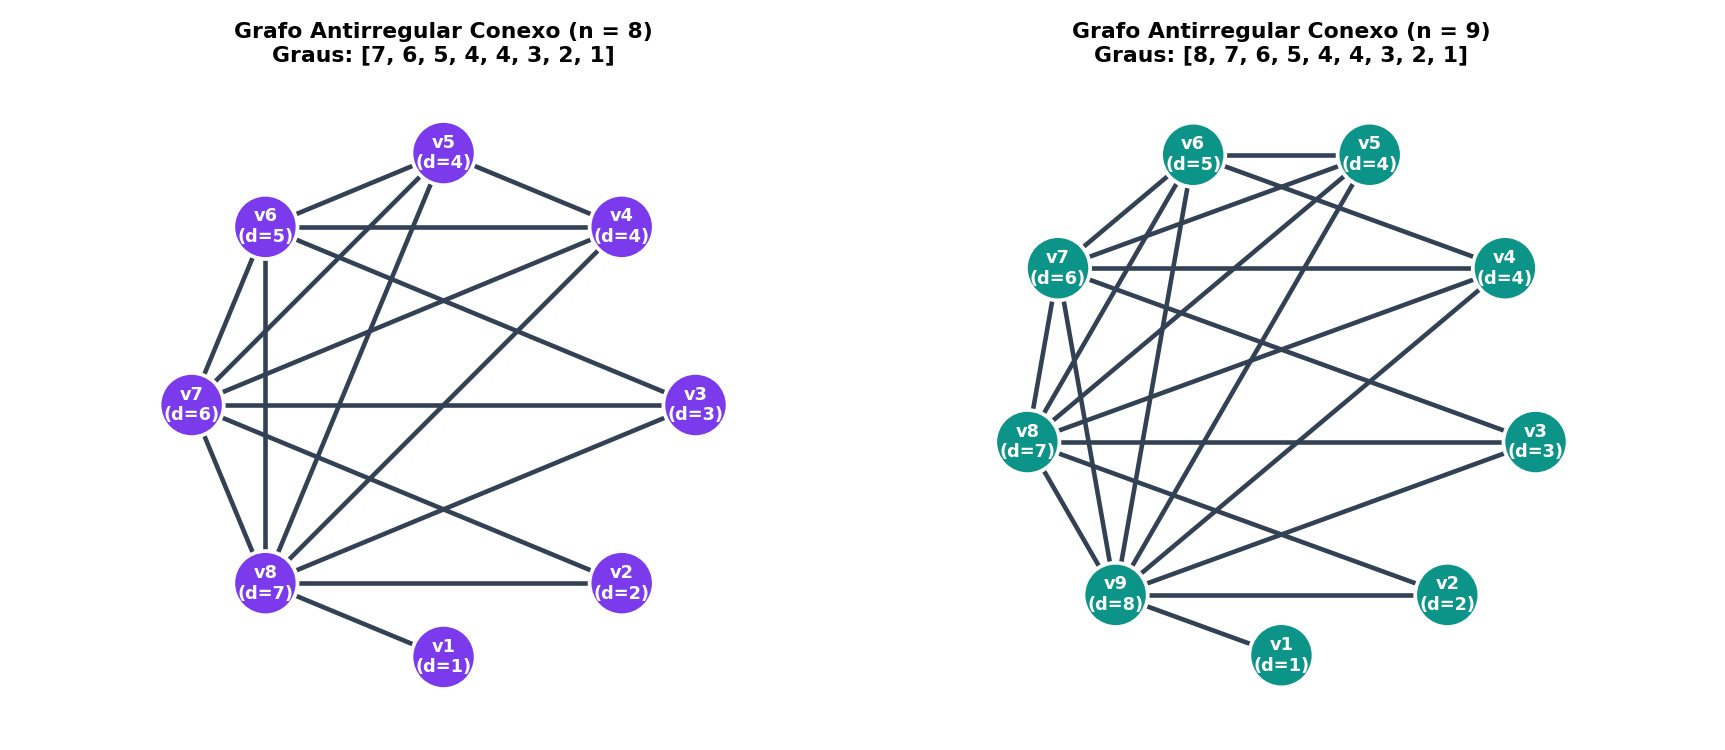

In [9]:
# Questão 16(c): Construção e verificação dos Grafos Antirregulares para n = 8 e n = 9
def construir_antirregular(n):
    vertices = list(range(1, n + 1))
    arestas = [(i, j) for i in vertices for j in vertices if i < j and (i + j >= n + 1)]
    graus = {v: 0 for v in vertices}
    for u, v in arestas:
        graus[u] += 1
        graus[v] += 1
    return vertices, arestas, graus

for n in [8, 9]:
    V_a, E_a, G_a = construir_antirregular(n)
    seq = sorted(G_a.values(), reverse=True)
    distintos = len(set(seq))
    print(f"=== Grafo Antirregular Conexo com n = {n} vértices ===")
    print(f"  Total de arestas: {len(E_a)}")
    print(f"  Sequência de graus: {seq}")
    print(f"  Quantidade de graus diferentes: {distintos} (= n - 1 = {n - 1})")
    print(f"  Grau repetido: {n // 2} (aparece 2 vezes)\n")